In [47]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

Chargez le fichier CSV

In [6]:
transactions = pd.read_csv("/content/drive/MyDrive/Dtasets/transactions_TP2.csv")

vérifier les données (Q: 1,2,3)

In [7]:
print("=========== dem de dataset============")
print(transactions.shape)
print("=========== les 5 pr lignes============")
print(transactions.head())
print("=========== les types  de variables============")
print(transactions.dtypes)
print("le nombre, le porcentage trée de valeurs manquantes ==========================")
N_V_manq= transactions.isnull().sum()
P_V_manq =  transactions.isnull().mean()*100
tabl_manq = pd.DataFrame(
    {"Nombre manquants": N_V_manq, "Pourcentage": P_V_manq}
).sort_values(by="Pourcentage", ascending=False)
print(tabl_manq)
print("le nombre de doublons avec  id_operation=========================")
N_doubl = transactions.duplicated(subset=['id_operation']).sum()
print(N_doubl)
delet_doubl = transactions.drop_duplicates(subset=['id_operation'], keep='first')
print("le nombre de lignes restantes.=========================")
print(len(delet_doubl))


=========== dem de dataset============
(3045, 12)
=========== les 5 pr lignes============
  id_operation id_client  montant_dh  anciennete_mois  nb_ops_24h  heure  \
0      OP02438    C10278     5396.62             90.0         6.0     11   
1      OP00157    C10019      438.41             55.0         2.0     22   
2      OP01987    C10604     2846.79              NaN         1.0     10   
3      OP00207    C10330      914.14            127.0         4.0      7   
4      OP00738    C10380      228.23            110.0         4.0      5   

         canal    appareil             region international resultat_enquete  \
0     site_web      mobile     Marrakech-Safi           non    aucune_fraude   
1  application      mobile        Souss-Massa           non    aucune_fraude   
2    telephone  ordinateur  Casablanca-Settat           non    aucune_fraude   
3  application      mobile  Casablanca-Settat           non    aucune_fraude   
4  application    terminal  Casablanca-Settat        


**histogramme du montant et un boxplot (Q4)**


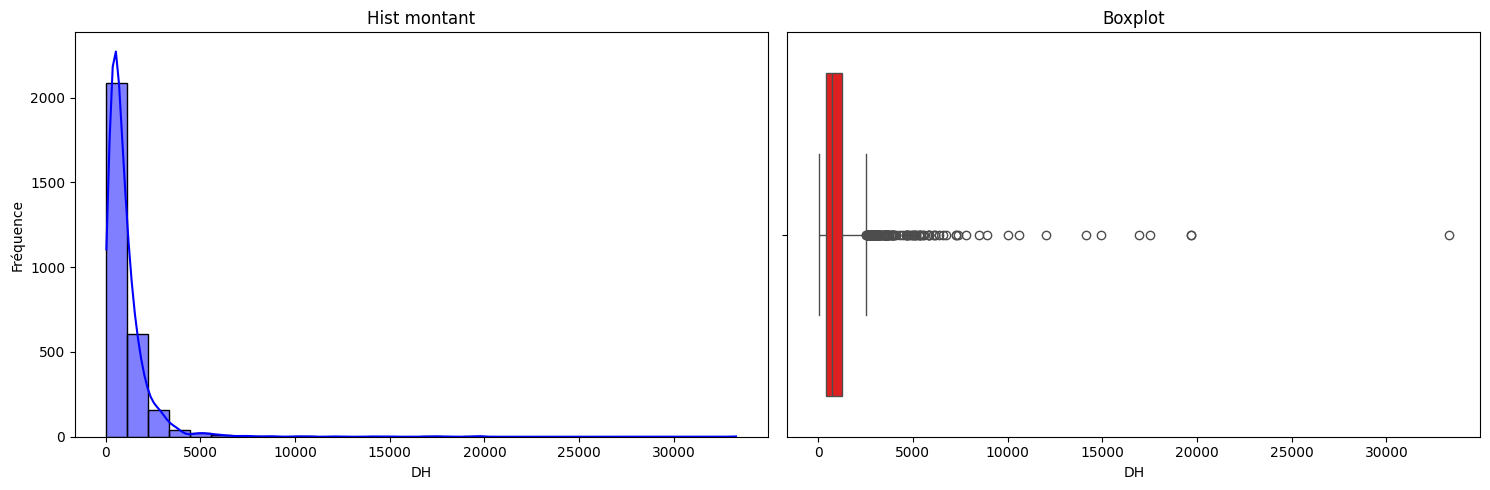

In [8]:
plt.figure(figsize=(15, 5))
#Histogramme
plt.subplot(1, 2, 1)
sns.histplot(transactions['montant_dh'], kde=True, bins=30, color='blue')
plt.title("Hist montant")
plt.xlabel("DH")
plt.ylabel("Fréquence")
#boxplot
plt.subplot(1, 2, 2)
sns.boxplot(x=transactions['montant_dh'], color='red')
plt.title("Boxplot")
plt.xlabel("DH")
plt.tight_layout()
plt.show()

 **Repérez quelques montants extrêmes. Faut-il
forcément les supprimer?**

Non, il ne faut pas forcément les supprimer. Dans les données bancaires, ces montants élevés ne sont pas toujours des erreurs : ils peuvent correspondre à de vraies transactions importantes (comme des achats faits par des clients riches). Si on les supprime, le modèle risque de rater des informations très importantes, surtout si on cherche à détecter des cas de fraude

Nombre de transactions par fraude :
fraude
0    2781
1     264
Name: count, dtype: int64

Pourcentage de chaque classe (%) :
fraude
0    91.330049
1     8.669951
Name: proportion, dtype: float64
==========diagrame=============


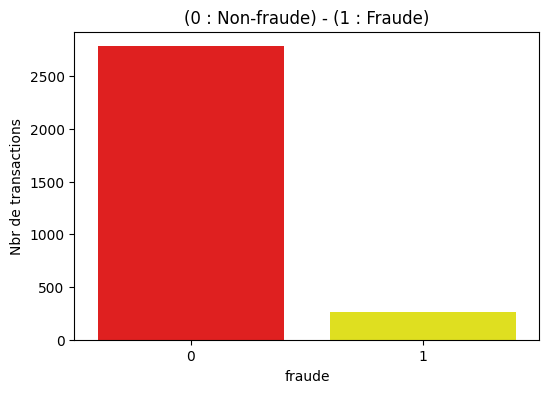

In [9]:
nbr_fraud = transactions['fraude'].value_counts()
porcentage_prop = transactions['fraude'].value_counts(normalize=True) * 100

print("Nombre de transactions par fraude :")
print(nbr_fraud)
print("\nPourcentage de chaque classe (%) :")
print(porcentage_prop)
print("==========diagrame=============")
plt.figure(figsize=(6, 4))
sns.countplot(x='fraude', data=transactions,hue='fraude', palette=['red', 'yellow'], legend=False)

plt.title("(0 : Non-fraude) - (1 : Fraude)")
plt.xlabel("fraude")
plt.ylabel("Nbr de transactions")
plt.show()

Question 6

Pourquoi les exclure : Les identifiants (comme id_operation) ne servent à rien pour prédire la fraude et risquent de perturber le modèle. La colonne resultat_enquete ne doit pas être incluse car c'est la réponse qu'on cherche à deviner (si on la met, le modèle va tricher).

Quand connaît-on resultat_enquete : On la connaît seulement après coup, suite à une vérification humaine, mais pas au moment où la transaction se produit.

**Partie 2**

séparation

In [12]:
y = transactions['resultat_enquete']
x = transactions.drop(columns=['resultat_enquete'])
x_train, x_test, y_train, y_test = train_test_split(x , y , test_size= 0.2 , random_state=42 )
print("y_train :", y_train.value_counts(normalize=True) * 100)

print("y_test :", y_test.value_counts(normalize=True) * 100)

y_train : resultat_enquete
aucune_fraude       91.297209
fraude_confirmee     8.702791
Name: proportion, dtype: float64
y_test : resultat_enquete
aucune_fraude       91.461412
fraude_confirmee     8.538588
Name: proportion, dtype: float64



**Question 9**

In [13]:
num_cols = x_train.select_dtypes(include=['int64', 'float64']).columns
categor_cols = x_train.select_dtypes(include=['object', 'category']).columns
print("numériques :", categor_cols)
print("catégorielles :", categor_cols)

numériques : Index(['id_operation', 'id_client', 'canal', 'appareil', 'region',
       'international'],
      dtype='object')
catégorielles : Index(['id_operation', 'id_client', 'canal', 'appareil', 'region',
       'international'],
      dtype='object')


 les catégories comme canal et
region ne doivent pas être traitées comme des nombres ordinaires
Parce que ce sont des variables qualitatives nominales sans ordre mathématique. Il faut utiliser le One-Hot Encoding.

**Q :10, 11 , 12**

In [18]:
num_trans = Pipeline(
    steps=[
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler()),
    ]
)

categ_trans = Pipeline(
    steps=[
        (
            'imputer', SimpleImputer(strategy='most_frequent'),
        ),
        (
            'onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False),
        ),
    ]
)

preproc = ColumnTransformer(
    transformers=[
        ('num', num_trans, num_cols),
        ('cat', categ_trans, categor_cols)
        ]
)

X_train_processed = preproc.fit_transform(x_train)
X_test_processed = preproc.transform(x_test)

print('Dim de X_train après transformation :', X_train_processed.shape)
print('Dim de X_test après transformation :', X_test_processed.shape)

Dim de X_train après transformation : (2436, 3211)
Dim de X_test après transformation : (609, 3211)


**Q14**

Si on calcule la médiane ou les paramètres de normalisation sur toutes les lignes (y compris le test), les données de test vont influencer les données d'entraînement.

Le problème :
Le modèle va tricher et aura de faux bons résultats lors de l'évaluation, mais il échouera sur de vraies nouvelles données car il a déjà vu des informations du test à l'avance (**fuite de données**).

**Q15:** calculer l'ecart

In [22]:
Q1 = x_train['montant_dh'].quantile(0.25)
Q3 = x_train['montant_dh'].quantile(0.75)
IQR = Q3 - Q1
print(f"Q1 = {Q1}")
print(f"Q3 = {Q3}")
print(f"IQR = {IQR}")

Q1 = 384.27
Q3 = 1244.9
IQR = 860.6300000000001


**L'IQR** mesure la dispersion des 50 % des valeurs centrales de la série. C'est l'intervalle entre le 3ème quartile (75%) et le 1er quartile (25%). Contrairement à l'écart-type, il n'est pas influencé par les valeurs extrêmes.

**Q 16:**

In [23]:
v_bas = Q1 - 1.5 * IQR
v_haut = Q3 + 1.5 * IQR

concernees = x_train[
    (x_train['montant_dh'] < v_bas) | (x_train['montant_dh'] > v_haut)
]

print(f"Nombre de lignes concernées : {len(concernees)}")

Nombre de lignes concernées : 148


**Sont-ils nécessairement des erreurs ?**
Non, ce ne sont pas forcément des erreurs. Ce sont des montants très élevés, mais dans le domaine bancaire, ils peuvent correspondre à de vraies transactions importantes (achats de clients riches ou professionnels).

**Q17 :**

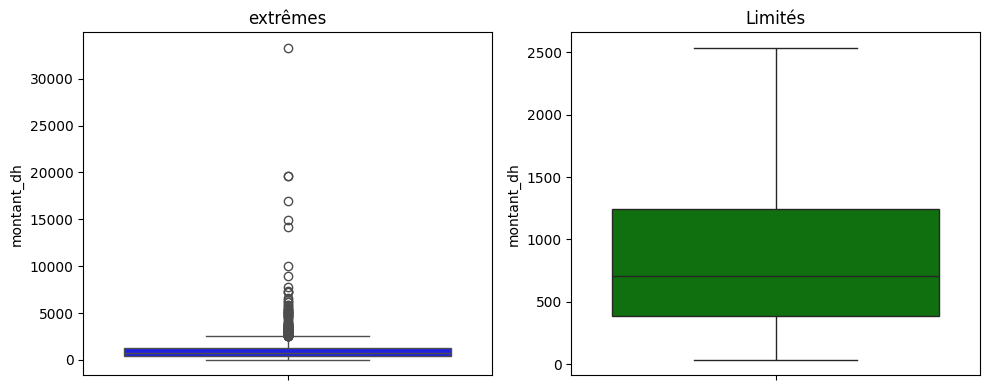

In [25]:
montant_extreme = x_train['montant_dh']

montant_limit = np.clip(x_train['montant_dh'], v_bas, v_haut)

plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
sns.boxplot(y=montant_extreme, color='blue')
plt.title('extrêmes')

plt.subplot(1, 2, 2)
sns.boxplot(y=montant_limit, color='green')
plt.title('Limités')

plt.tight_layout()
plt.show()

Il faut justifier ce choix car dans la détection de fraude, les montants très élevés ne sont pas forcément des erreurs. Ils peuvent correspondre à de vrais achats importants ou à des comportements suspects. Si on les supprime ou qu'on les bloque trop brutalement, le modèle risque de perdre des informations cruciales pour détecter la fraude.

**Q18 :**

In [30]:
scaler_minmax = MinMaxScaler()
scaler_standard = StandardScaler()
scaler_robust = RobustScaler()
# appliquer sur une seule colonne
montant_train = x_train[['montant_dh']]
montant_test = x_test[['montant_dh']]
# 1.fit sur train et transformer le test
scaler_minmax.fit(montant_train)
montant_minmax_test = scaler_minmax.transform(montant_test)
#_____minmax_______
scaler_minmax.fit(montant_train)
m_minmax = scaler_minmax.transform(montant_test)
#_____standard_______
scaler_standard.fit(montant_train)
m_std = scaler_standard.transform(montant_test)
#______robust______
scaler_robust.fit(montant_train)
m_rob = scaler_robust.transform(montant_test)

**Q19: examples**

In [31]:
exemples = pd.DataFrame(
    {'montant_dh': [100, 500, 1000, 25000]}
)

Q19 = pd.DataFrame()
Q19['Valeur_Brute'] = exemples['montant_dh']
Q19['MinMax'] = scaler_minmax.transform(exemples)
Q19['StandardScaler (Z-score)'] = scaler_standard.transform(exemples)
Q19['RobustScaler'] = scaler_robust.transform(exemples)

print(Q19)

   Valeur_Brute    MinMax  StandardScaler (Z-score)  RobustScaler
0           100  0.001913                 -0.676881     -0.708376
1           500  0.013945                 -0.383925     -0.243601
2          1000  0.028985                 -0.017729      0.337369
3         25000  0.750902                 17.559667     28.223917


**La méthode la plus perturbée :** MinMaxScaler.

**justification :** Le MinMaxScaler est le plus sensible aux valeurs extrêmes parce qu'il se base uniquement sur les valeurs extrêmes elles-mêmes (min et max). Ainsi, un seul montant anormalement grand va modifier totalement l'échelle et comprimer toutes les autres données dans une plage très étroite proche de zéro.

**Q20 : **

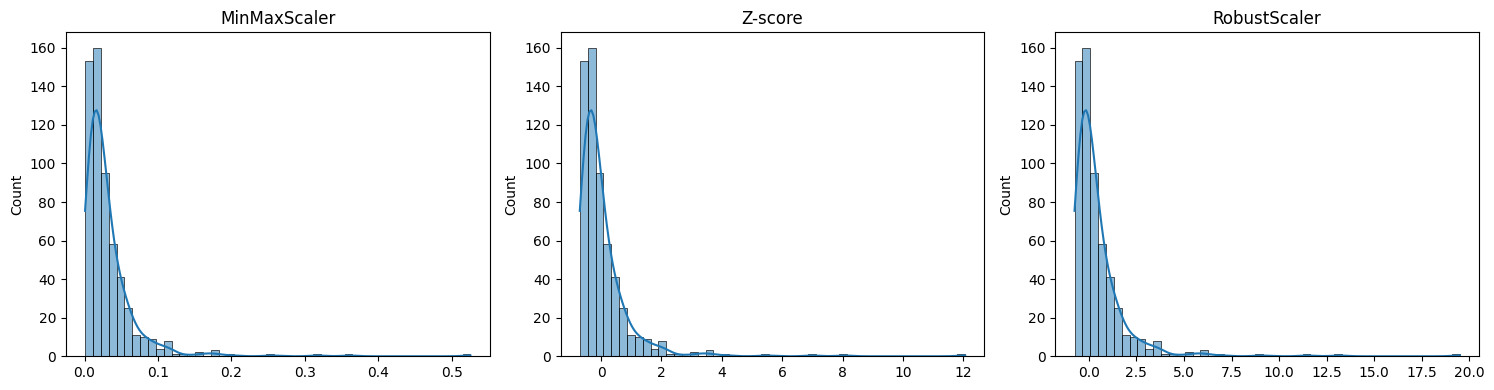

In [36]:
plt.figure(figsize=(15, 4))

plt.subplot(1, 3, 1)
sns.histplot(m_minmax, kde=True, legend=False)
plt.title('MinMaxScaler')

plt.subplot(1, 3, 2)
sns.histplot(m_std, kde=True, legend=False)
plt.title('Z-score')

plt.subplot(1, 3, 3)
sns.histplot(m_rob, kde=True, legend=False)
plt.title('RobustScaler')

plt.tight_layout()
plt.show()

**Q21 :**

Suppos que dans le groupe d'entraînement (référence), les montants varient entre un min de 100 DH et un max de 1000 DH.
La formule du Min-Max est :$$\frac{x - \text{min}}{\text{max} - \text{min}}$$Si une nouvelle transaction arrive avec un montant de 1450 DH (qui dépasse le max de 1000 DH), le calcul donne :$$\frac{1450 - 100}{1000 - 100} = \frac{1350}{900} = \mathbf{1,5}$$

In [37]:
nouveau_montant = pd.DataFrame({'montant_dh': [50000]})
print(scaler_minmax.transform(nouveau_montant))

[[1.5028985]]


Alors est Oui, sa valeur transformée peut dépasser 1.

MinMaxScaler mémorise uniquement le min et le max du groupe d'entraînement (fit). Il ne "bloque" pas les nouvelles données entre 0 et 1 : il applique simplement sa formule mathématique. Donc, si une nouvelle valeur dans le groupe de test est plus grande que le maximum connu lors de l'entraînement, le résultat sera automatiquement supérieur à 1.

**Partie 4 : Préparer des classes déséquilibrées**

**Q22 :** Compter les lignes dans

In [38]:
counts = y_train.value_counts()
print(counts)

# le rapport entre les deux classes (majoritaire / minoritaire)
rapport = counts.iloc[0] / counts.iloc[1]
print(f"Rapport entre les deux classes : {rapport:.2f}")

resultat_enquete
aucune_fraude       2224
fraude_confirmee     212
Name: count, dtype: int64
Rapport entre les deux classes : 10.49


**Q23:**  oversampling

In [43]:
r_o_s = RandomOverSampler(random_state=42)
x_train_over, y_train_over = r_o_s.fit_resample(x_train, y_train)

print("Avant oversampling :", y_train.value_counts().to_dict())
print("Après oversampling :", pd.Series(y_train_over).value_counts().to_dict())

Avant oversampling : {'aucune_fraude': 2224, 'fraude_confirmee': 212}
Après oversampling : {'aucune_fraude': 2224, 'fraude_confirmee': 2224}


**Nombre de lignes :** Après application, le nombre de lignes de la classe minoritaire augmente pour s'égaliser avec la classe majoritaire.

**Sont-ce des copies ?** Oui, les nouvelles lignes générées par RandomOverSampler sont de simples copies exactes de lignes existantes de la classe minoritaire tirées au hasard.

**Q24 :** undersampling

In [46]:
r_u_s = RandomUnderSampler(random_state=42)
x_train_under, y_train_under = r_u_s.fit_resample(x_train, y_train)

print("Après undersampling :", pd.Series(y_train_under).value_counts().to_dict())

Après undersampling : {'aucune_fraude': 212, 'fraude_confirmee': 212}


**Principe :** Il réduit aléatoirement le nombre de lignes de la classe majoritaire pour l'égaliser avec la classe minoritaire (beaucoup de lignes normales sont donc supprimées).

**Quel est le risque ?** Le principal risque est la perte d'informations importantes

**Q25**: SMOTE

**Ce que fait SMOTE :** Au lieu de copier une ligne existante, il crée de nouveaux points artificiels (synthétiques) entre les voisins proches de la classe minoritaire(KNN) grâce à une moyenne (interpolation).

**Pourquoi ce n'est pas une copie :** Les valeurs obtenues sont de nouvelles valeurs calculées mathématiquement et non un simple copier-coller.

In [57]:
x_train_num = x_train.select_dtypes(include=['number'])

x_train_num = x_train_num.fillna(x_train_num.mean())

smote = SMOTE(random_state=42)
x_train_smote, y_train_smote = smote.fit_resample(x_train_num, y_train)

print("Après SMOTE :", pd.Series(y_train_smote).value_counts().to_dict())

Après SMOTE : {'aucune_fraude': 2224, 'fraude_confirmee': 2224}


**Q26:**

Pourquoi faire attention avec le One-Hot Encoding : SMOTE calcule des distances entre les points. Si on applique SMOTE sur des variables binaires (0 ou 1 issues du One-Hot), la création d'un point "intermédiaire" va générer des valeurs décimales (par exemple 0.4 ou 0.7), ce qui n'a aucun sens pour des catégories binaires.

Méthode conçue pour les données mixtes : On utilise SMOTENC (Synthetic Minority Over-sampling Technique for Nominal and Continuous), qui est spécialement conçue pour gérer à la fois des variables numériques et des variables catégorielles.

**Q27 :**

In [58]:
comparaison_classes = pd.DataFrame(
    {
        'Avant rééquilibrage': y_train.value_counts().sort_index(),
        'Après Oversampling ': pd.Series(y_train_over).value_counts().sort_index(),
        'Après Undersampling ': pd.Series(y_train_under).value_counts().sort_index(),
    }
)
print(comparaison_classes)

                  Avant rééquilibrage  Après Oversampling   \
resultat_enquete                                             
aucune_fraude                    2224                 2224   
fraude_confirmee                  212                 2224   

                  Après Undersampling   
resultat_enquete                        
aucune_fraude                      212  
fraude_confirmee                   212  


Le groupe de vérification doit-il changer ?**Non**, le groupe de vérification (X_test / y_test) ne doit jamais être modifié ni rééquilibré.

**Justification :** Le jeu de test doit refléter la réalité du terrain (qui est fortement déséquilibrée). Si on modifie le test, on fausse l'évaluation finale et le modèle ne sera pas testé sur des conditions réelles.

**Partie 5 — Vérifier et enregistrer les données préparées**


**Q28 :**  version finale de ColumnTransformer

In [61]:
numeric_features = x_train.select_dtypes(include=['number']).columns
categorical_features = x_train.select_dtypes(
    include=['object', 'category']
).columns

preprocessor = ColumnTransformer(
    transformers=[
        (
            'num',
            Pipeline(
                steps=[
                    (
                        'imputer',
                        SimpleImputer(strategy='median'),
                    ),
                    ('scaler', RobustScaler()),
                ]
            ),
            numeric_features,
        ),
        (
            'cat',
            Pipeline(
                steps=[
                    (
                        'imputer',
                        SimpleImputer(strategy='most_frequent'),
                    ),
                    (
                        'onehot',
                        OneHotEncoder(handle_unknown='ignore', sparse_output=False),
                    ),
                ]
            ),
            categorical_features,
        ),
    ]
)
print('ColumnTransformer succès ')

ColumnTransformer succès 


**Q29 :** les paramètres du transformateur final

In [63]:
x_train_processed = preprocessor.fit_transform(x_train)
x_test_processed = preprocessor.transform(x_test)

print("Nombre de colonnes après transformation (Train) :", X_train_processed.shape[1])
print("Nombre de colonnes après transformation (Test) :", X_test_processed.shape[1])
print("Valeurs NaN dans Train :", np.isnan(x_train_processed).sum())
print("Valeurs NaN dans Test :", np.isnan(x_test_processed).sum())

Nombre de colonnes après transformation (Train) : 3211
Nombre de colonnes après transformation (Test) : 3211
Valeurs NaN dans Train : 0
Valeurs NaN dans Test : 0


**Q30 :**

In [65]:
exemple_inconnu = x_test.iloc[:5].copy()

colon_new = x_test.select_dtypes(
    include=['object', 'category']
).columns[0]
exemple_inconnu.iloc[0, exemple_inconnu.columns.get_loc(colon_new)] = (
    'valeur_inconnue_test'
)

# Vérifiez que OneHotEncoder peut transformer cette ligne sans erreur
x_test_transformed = preprocessor.transform(exemple_inconnu)

print('Simulation réussie sans erreur ')
print("Dim des données transformées :", x_test_transformed.shape)

Simulation réussie sans erreur 
Dim des données transformées : (5, 3211)


**Q31. Enregistrez le transformateur**

In [66]:
import joblib
joblib.dump(preprocessor, 'preprocessor_fraude.pkl')

loaded_preprocessor = joblib.load('preprocessor_fraude.pkl')

echantillon = x_test.iloc[:5]

res_original = preprocessor.transform(echantillon)
res_rechargé = loaded_preprocessor.transform(echantillon)

# Comparé
sont_identiques = np.allclose(res_original, res_rechargé)
print("Les valeurs rechargées sont-elles identiques ? :", sont_identiques)

Les valeurs rechargées sont-elles identiques ? : True


La sauvegarde avec joblib permet de figer les paramètres appris (médianes, échelles). Le rechargement applique exactement les mêmes transformations sur de nouvelles données sans tout recalculer, ce qui garantit la cohérence en production.